# Desafío Tiendas Super Niño — Marketing

**Analítica de Datos · Negocios Digitales · UdeSA**

## El caso
Super Niño tiene clientes recurrentes que abandonan el carrito. Muchos vuelven solos en 72 horas y otros no. Marketing puede mandar un cupón de descuento: recupera a quien no iba a volver, pero lo recibe cualquiera, incluso quien igual volvía, y el presupuesto alcanza para pocos cupones por lote.

**Pregunta a responder:** ¿A qué carritos abandonados del lote les mandamos el cupón para maximizar el beneficio?

**Datos disponibles:** `historico.csv` (con resultado) y `casos_nuevos.csv` (sin resultado, es lo que hay que decidir hoy).

**Variable a predecir:** `no_volvio` (en el archivo original, `nv_72h`)

**Restricción clave:** 90 cupones por lote. Cada venta no recuperada pierde $9.000 de margen; cada cupón usado cuesta $1.500.

> Recordatorio: gana el equipo que toma la mejor decisión de negocio, no el que escribe más código. Cada decisión de este notebook tiene que poder explicarse en voz alta.

| Stream | Secciones |
|---|---|
| A. EDA | 1 y 2 (ya armadas: hay que interpretarlas) |
| B. Modelado | 3, 4 y 5 |
| C. Comunicación | 6 y 7 |

## 0. Setup

Librerías, semilla y los números del metadata (costos y cupo) en un solo lugar, para no tener que volver a buscarlos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Datos del metadata
MARGEN_PERDIDO = 9000    # margen que se pierde por cada carrito no recuperado
DESCUENTO_CUPON = 1500   # costo por cupón usado
CUPO = 90                # cupones por lote

In [2]:
def pesos(x):
    return "$" + f"{x:,.0f}".replace(",", ".")


def tabla_tasa(df, col, objetivo):
    return df.groupby(col, observed=True, dropna=False)[objetivo].agg(tasa="mean", n="count")


def grafico_tasa(df, col, objetivo, ax):
    tabla = tabla_tasa(df, col, objetivo)
    etiquetas = []
    for valor in tabla.index:
        if pd.isna(valor):
            etiquetas.append("sin dato")
        else:
            etiquetas.append(str(valor))
    ax.bar(etiquetas, tabla["tasa"] * 100, color="#4C72B0")
    ax.axhline(df[objetivo].mean() * 100, color="red", linestyle="--", label="promedio general")
    for i in range(len(tabla)):
        ax.text(i, tabla["tasa"].iloc[i] * 100 + 1, f"n={tabla['n'].iloc[i]}", ha="center", fontsize=8)
    ax.set_title(col)
    ax.set_ylabel(f"% con {objetivo}")
    ax.set_ylim(0, 105)
    ax.tick_params(axis="x", labelrotation=30)
    ax.legend()


def grilla_tasas(df, columnas, objetivo, ancho=5):
    fig, axes = plt.subplots(1, len(columnas), figsize=(ancho * len(columnas), 4), squeeze=False)
    for ax, col in zip(axes[0], columnas):
        grafico_tasa(df, col, objetivo, ax)
    plt.tight_layout()
    plt.show()


def mapa_tasa(df, fila, columna, objetivo, ax, n_min=5):
    tasa = df.pivot_table(index=fila, columns=columna, values=objetivo, aggfunc="mean", observed=True) * 100
    n = df.pivot_table(index=fila, columns=columna, values=objetivo, aggfunc="count", observed=True)
    # celdas con pocos casos: sin color (0) pero con su n anotado; celdas sin casos: vacías
    tasa_vista = tasa.where(n >= n_min, 0).where(n.notna())
    etiquetas = np.full(tasa.shape, "", dtype=object)
    for i in range(tasa.shape[0]):
        for j in range(tasa.shape[1]):
            cantidad = n.iloc[i, j]
            if np.isnan(cantidad):
                continue
            if cantidad < n_min:
                etiquetas[i, j] = f"n={int(cantidad)}"
            else:
                etiquetas[i, j] = f"{tasa.iloc[i, j]:.0f}%\n(n={int(cantidad)})"
    sns.heatmap(tasa_vista, annot=etiquetas, fmt="", cmap="Reds", vmin=0, vmax=100,
                cbar_kws={"label": f"% con {objetivo}"}, ax=ax)
    ax.grid(False)
    ax.set_title(f"{fila} x {columna}")


def intervalo_wilson(exitos, n, z=1.96):
    p = exitos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen


def grafico_intervalos(df, col, objetivo, ax):
    grupos = df.groupby(col, observed=True)[objetivo].agg(["sum", "count"])
    for i in range(len(grupos)):
        inferior, superior = intervalo_wilson(grupos["sum"].iloc[i], grupos["count"].iloc[i])
        tasa = grupos["sum"].iloc[i] / grupos["count"].iloc[i]
        ax.plot([inferior * 100, superior * 100], [i, i], color="#4C72B0", linewidth=2)
        ax.plot(tasa * 100, i, "o", color="#4C72B0")
    ax.axvline(df[objetivo].mean() * 100, color="red", linestyle="--", label="promedio general")
    ax.set_yticks(range(len(grupos)))
    ax.set_yticklabels([str(valor) for valor in grupos.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% (con intervalo de confianza del 95%)")
    ax.set_title(col)
    ax.legend()


def grilla_intervalos(df, columnas, objetivo, ncols=2, alto=3.6):
    filas = int(np.ceil(len(columnas) / ncols))
    fig, axes = plt.subplots(filas, ncols, figsize=(6 * ncols, alto * filas), squeeze=False)
    for ax, col in zip(axes.ravel(), columnas):
        grafico_intervalos(df, col, objetivo, ax)
    plt.tight_layout()
    plt.show()


def curva_riesgo(df, col, objetivo, ax, grupos=8):
    datos = df[[col, objetivo]].dropna().copy()
    datos["tramo"] = pd.qcut(datos[col], grupos, duplicates="drop")
    resumen = datos.groupby("tramo", observed=True).agg(x=(col, "median"), exitos=(objetivo, "sum"), n=(objetivo, "count"))
    tasas = (resumen["exitos"] / resumen["n"] * 100).to_numpy()
    inferior = np.zeros(len(resumen))
    superior = np.zeros(len(resumen))
    for i in range(len(resumen)):
        bajo, alto = intervalo_wilson(resumen["exitos"].iloc[i], resumen["n"].iloc[i])
        inferior[i] = bajo * 100
        superior[i] = alto * 100
    ax.errorbar(resumen["x"], tasas, yerr=[tasas - inferior, superior - tasas], fmt="-o", capsize=3, label="% por grupo (con IC 95%)")
    ax.axhline(df[objetivo].mean() * 100, color="red", linestyle="--", label="promedio general")
    ax.set_xlabel(f"{col} (mediana de cada grupo)")
    ax.set_ylabel(f"% con {objetivo}")
    ax.set_ylim(0, 100)
    ax.set_title(col)
    ax.legend()


def grilla_curvas(df, columnas, objetivo, ancho=6):
    fig, axes = plt.subplots(1, len(columnas), figsize=(ancho * len(columnas), 4), squeeze=False)
    for ax, col in zip(axes[0], columnas):
        curva_riesgo(df, col, objetivo, ax)
    plt.tight_layout()
    plt.show()


def auc_individual(df, col, objetivo):
    if pd.api.types.is_numeric_dtype(df[col]):
        x = df[col].fillna(-1)
    else:
        categoria = df[col].astype(object).fillna("sin dato").astype(str)
        x = categoria.map(df.groupby(categoria)[objetivo].mean())
    auc = roc_auc_score(df[objetivo], x)
    return max(auc, 1 - auc)

## 1. Carga

Leemos los dos archivos y **ya les renombramos las columnas** con nombres claros (en el diccionario `NOMBRES` está la equivalencia con el metadata). Usen estos nombres de acá en adelante.

También armamos variables derivadas de la fecha del abandono (día de la semana y franja horaria) y agrupamos algunas variables numéricas en tramos para poder graficarlas. Todo eso existe al momento del abandono, así que es información válida para decidir.

In [3]:
RUTA = "Dataset - Marketing/"

NOMBRES = {
    "ID_cli": "cliente_id",
    "TsAband": "fecha_abandono",
    "nCompras": "compras_previas",
    "diasUC": "dias_ultima_compra",
    "tkt": "valor_carrito",
    "nSku": "skus_carrito",
    "etp": "paso_abandono",
    "shipFee": "costo_envio_visto",
    "dsp": "dispositivo",
    "mailOp": "abrio_mail_30d",
    "prv": "origen",
    "ses7": "sesiones_7d",
    "cupN": "cupones_previos",
    "sesPost72": "sesiones_post_72h",
    "mailRem": "abrio_recordatorio",
    "csCtc": "contacto_atencion",
    "nv_72h": "no_volvio",
}

historico = pd.read_csv(RUTA + "historico.csv", parse_dates=["TsAband"]).rename(columns=NOMBRES)
nuevos = pd.read_csv(RUTA + "casos_nuevos.csv", parse_dates=["TsAband"]).rename(columns=NOMBRES)

print("historico:", historico.shape, "| casos nuevos:", nuevos.shape)
print("Columnas que están en el histórico y NO en casos nuevos:", set(historico.columns) - set(nuevos.columns))
historico.head()

historico: (374, 17) | casos nuevos: (124, 16)
Columnas que están en el histórico y NO en casos nuevos: {'no_volvio'}


,cliente_id,fecha_abandono,compras_previas,dias_ultima_compra,valor_carrito,skus_carrito,paso_abandono,costo_envio_visto,dispositivo,abrio_mail_30d,origen,sesiones_7d,cupones_previos,sesiones_post_72h,abrio_recordatorio,contacto_atencion,no_volvio
0,C512407,2026-09-07 05:18:12,4,21.0,64200,2,PAG,0,dsk,0,INT,1.0,0,4,0,0,0
1,C761952,2026-09-07 08:53:42,4,35.0,53000,3,CAR,0,mob,1,INT,1.0,1,1,1,0,1
2,C125370,2026-09-07 09:01:57,2,41.0,60800,2,PAG,0,dsk,0,GBA,4.0,1,0,1,1,0
3,C597301,2026-09-07 14:21:26,2,113.0,36200,2,CAR,0,NaN,1,GBA,2.0,0,4,0,0,0
4,C451692,2026-09-07 15:13:06,5,53.0,42500,2,ENV,5900,app,1,CABA,2.0,0,3,0,0,0


In [4]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
FRANJAS = ["madrugada (0-5)", "mañana (6-11)", "tarde (12-17)", "noche (18-23)"]

for df in (historico, nuevos):
    df["hora"] = df["fecha_abandono"].dt.hour
    df["dia_semana"] = pd.Categorical.from_codes(df["fecha_abandono"].dt.dayofweek, categories=DIAS, ordered=True)
    df["franja_horaria"] = pd.cut(df["hora"], bins=[-1, 5, 11, 17, 23], labels=FRANJAS)
    df["tiene_costo_envio"] = (df["costo_envio_visto"] > 0).astype(int)
    df["compras_tramo"] = pd.cut(df["compras_previas"], bins=[0, 2, 3, 5, 100], labels=["2", "3", "4-5", "6 o más"])
    df["dias_uc_tramo"] = pd.cut(df["dias_ultima_compra"], bins=[0, 15, 30, 60, 120, 10000],
                                 labels=["hasta 15", "16-30", "31-60", "61-120", "más de 120"])
    df["sesiones_tramo"] = pd.cut(df["sesiones_7d"], bins=[-1, 0, 1, 3, 100], labels=["0", "1", "2-3", "4 o más"])

historico["valor_quintil"] = pd.qcut(historico["valor_carrito"], 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
historico.dtypes

cliente_id                       str
fecha_abandono        datetime64[us]
compras_previas                int64
dias_ultima_compra           float64
valor_carrito                  int64
skus_carrito                   int64
paso_abandono                    str
costo_envio_visto              int64
dispositivo                      str
abrio_mail_30d                 int64
origen                           str
sesiones_7d                  float64
cupones_previos                int64
sesiones_post_72h              int64
abrio_recordatorio             int64
contacto_atencion              int64
no_volvio                      int64
hora                           int32
dia_semana                  category
franja_horaria              category
tiene_costo_envio              int64
compras_tramo               category
dias_uc_tramo               category
sesiones_tramo              category
valor_quintil               category
dtype: object

**Observación:** el histórico trae una columna que `casos_nuevos` no tiene. Fijense más abajo (2.4) qué otras columnas existen en `casos_nuevos` pero vienen **vacías**, y qué significa eso para qué podemos usar al predecir.

## 2. EDA

**Stream A.** Acá el EDA ya está armado y corrido, con más análisis de los que hacen falta. Su trabajo no es escribirlo: es **leerlo, filtrar y quedarse con lo que importa para la decisión**.

Cómo trabajarlo:

1. Recorran los bloques en orden. Cada uno termina con un **Qué veo** para que anoten lo que encuentran.
2. **No todo gráfico trae un insight.** Parte del trabajo es descartar lo que es ruido o no cambia la decisión.
3. Miren siempre el **n** (cantidad de casos). Un grupo de 5 o 10 casos que "se ve muy alto" no es un patrón, es una anécdota.
4. Un insight tiene tres partes: **qué encontramos**, **con qué número** y **qué cambia en la decisión** (a cuántos clientes y a cuáles les mandamos el cupón).
5. Al final (2.16) eligen los 2 o 3 mejores insights, más el inesperado, y definen qué variables entran al modelo.

En todos los gráficos de barras la línea roja es el promedio general: lo que importa es qué tan lejos de esa línea queda cada grupo.

### 2.1 Dimensionar el problema

Antes de buscar patrones: ¿qué tan seguido pasa y cuánta plata mueve? Esto fija contra qué tenemos que ganar. Cualquier regla de decisión tiene que ser mejor que **no mandar ningún cupón** y mejor que **mandar cupón a todos**.

In [5]:
N_HIST = len(historico)
N_NUEVOS = len(nuevos)
tasa_no_volvio = historico["no_volvio"].mean()

print(f"Histórico: {N_HIST} carritos | {historico['no_volvio'].sum()} clientes no volvieron | tasa de no retorno: {tasa_no_volvio:.1%}")

no_vuelven_esperados = tasa_no_volvio * N_NUEVOS
filas = [
    ("Carritos abandonados en el lote nuevo", N_NUEVOS),
    ("Clientes que no volverían si se repite la tasa histórica", round(no_vuelven_esperados)),
    ("Margen perdido esperado si no se manda ningún cupón", pesos(no_vuelven_esperados * MARGEN_PERDIDO)),
    ("Costo de los cupones si TODOS los clientes del lote lo usaran", pesos(N_NUEVOS * DESCUENTO_CUPON)),
    ("Cupo de cupones, como % del lote", f"{CUPO / N_NUEVOS:.0%}"),
    ("Costo de usar el cupo completo (si todos lo usan)", pesos(CUPO * DESCUENTO_CUPON)),
]
pd.DataFrame(filas, columns=["concepto", "valor"])

Histórico: 374 carritos | 110 clientes no volvieron | tasa de no retorno: 29.4%


,concepto,valor
0,Carritos abandonados en el lote nuevo,124
1,Clientes que no volverían si se repite la tasa...,36
2,Margen perdido esperado si no se manda ningún ...,$328.235
3,Costo de los cupones si TODOS los clientes del...,$186.000
4,"Cupo de cupones, como % del lote",73%
5,Costo de usar el cupo completo (si todos lo usan),$135.000


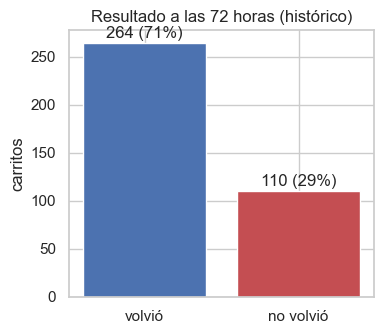

In [6]:
conteo = historico["no_volvio"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["volvió", "no volvió"], conteo.values, color=["#4C72B0", "#C44E52"])
for i in range(len(conteo)):
    ax.text(i, conteo.values[i] + 5, f"{conteo.values[i]} ({conteo.values[i] / N_HIST:.0%})", ha="center")
ax.set_ylabel("carritos")
ax.set_title("Resultado a las 72 horas (histórico)")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué porcentaje no vuelve? ¿Qué desbalance hay entre las clases y qué implica para elegir métricas? Comparen el cupo con el tamaño del lote: ¿el presupuesto es una restricción fuerte o suave? ¿Conviene mandar cupón a todos?_

### 2.2 Calidad de los datos

No hay que hacer limpieza como tal (no llegan los tiempos), pero **sí hay que saber qué hay**: cada rareza obliga a una decisión (la dejo, la acoto, la ignoro) y la tienen que poder justificar.

Ojo con el reflejo que traemos de regresión lineal (Clase 04): ahí un valor extremo distorsiona la recta y se saca. Acá vamos a usar árboles, que cortan por umbrales y no se "rompen" con extremos. Antes de borrar algo hay que preguntarse si es un error de carga o un caso real que forma parte de la señal.

Tres revisiones: nulos, valores extremos y consistencia entre columnas.

In [7]:
nulos = pd.DataFrame({
    "nulos histórico": historico.isna().sum(),
    "% histórico": historico.isna().mean() * 100,
    "nulos casos nuevos": nuevos.isna().sum(),
    "% casos nuevos": nuevos.isna().mean() * 100,
}).round(1)
nulos[(nulos["nulos histórico"] > 0) | (nulos["nulos casos nuevos"] > 0)]

,nulos histórico,% histórico,nulos casos nuevos,% casos nuevos
abrio_recordatorio,0,0.0,124.0,100.0
contacto_atencion,0,0.0,124.0,100.0
dias_uc_tramo,19,5.1,6.0,4.8
dias_ultima_compra,19,5.1,6.0,4.8
dispositivo,10,2.7,5.0,4.0
sesiones_7d,13,3.5,7.0,5.6
sesiones_post_72h,0,0.0,124.0,100.0
sesiones_tramo,13,3.5,7.0,5.6


,count,mean,std,min,1%,50%,99%,max
compras_previas,374.0,3.8,2.3,2.0,2.0,3.0,12.3,15.0
dias_ultima_compra,355.0,92.0,194.8,4.0,6.5,51.0,572.3,2000.0
valor_carrito,374.0,64838.5,63287.7,5400.0,9365.0,49250.0,352859.0,639000.0
skus_carrito,374.0,2.0,0.9,1.0,1.0,2.0,5.0,5.0
sesiones_7d,361.0,2.2,1.5,0.0,0.0,2.0,6.0,8.0
cupones_previos,374.0,0.8,0.9,0.0,0.0,1.0,4.0,4.0


Los 8 valores más altos de dias_ultima_compra:


,dias_ultima_compra,compras_previas,paso_abandono,no_volvio
51,2000.0,3,CAR,0
64,2000.0,3,ENV,0
278,2000.0,15,ENV,0
269,670.0,2,ENV,1
57,489.0,7,CAR,0
242,455.0,4,ENV,1
223,392.0,4,PAG,0
220,365.0,6,PAG,1


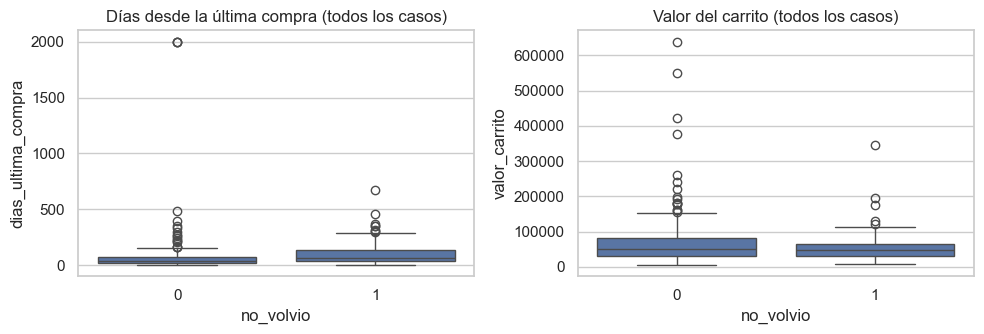

In [8]:
numericas = ["compras_previas", "dias_ultima_compra", "valor_carrito", "skus_carrito", "sesiones_7d", "cupones_previos"]
display(historico[numericas].describe(percentiles=[0.01, 0.5, 0.99]).T.round(1))

print("Los 8 valores más altos de dias_ultima_compra:")
display(historico.nlargest(8, "dias_ultima_compra")[["dias_ultima_compra", "compras_previas", "paso_abandono", "no_volvio"]])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(data=historico, x="no_volvio", y="dias_ultima_compra", ax=axes[0])
axes[0].set_title("Días desde la última compra (todos los casos)")
sns.boxplot(data=historico, x="no_volvio", y="valor_carrito", ax=axes[1])
axes[1].set_title("Valor del carrito (todos los casos)")
plt.tight_layout()
plt.show()

In [9]:
print("Valores de costo_envio_visto:")
display(historico["costo_envio_visto"].value_counts().sort_index())
print("Costo de envío visto según el paso en que abandonó (cantidad de carritos):")
display(pd.crosstab(historico["paso_abandono"], historico["tiene_costo_envio"].map({0: "costo 0", 1: "costo mayor a 0"})))

print("\nClientes con menos de 2 compras previas (la política apunta a recurrentes):", (historico["compras_previas"] < 2).sum())
print("Clientes repetidos en el histórico:", historico["cliente_id"].duplicated().sum())
print("Clientes que están en histórico y en casos nuevos:", len(set(historico["cliente_id"]) & set(nuevos["cliente_id"])))
print("Fechas histórico:", historico["fecha_abandono"].min().date(), "a", historico["fecha_abandono"].max().date())
print("Fechas casos nuevos:", nuevos["fecha_abandono"].min().date(), "a", nuevos["fecha_abandono"].max().date())

Valores de costo_envio_visto:


costo_envio_visto
0       214
3200     58
4500     56
5900     46
Name: count, dtype: int64

Costo de envío visto según el paso en que abandonó (cantidad de carritos):


tiene_costo_envio,costo 0,costo mayor a 0
paso_abandono,,
CAR,114,0
ENV,48,77
PAG,52,83



Clientes con menos de 2 compras previas (la política apunta a recurrentes): 0
Clientes repetidos en el histórico: 0
Clientes que están en histórico y en casos nuevos: 0
Fechas histórico: 2026-09-07 a 2026-10-25
Fechas casos nuevos: 2026-09-07 a 2026-10-25


**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué columnas tienen nulos? ¿Hay valores de `dias_ultima_compra` que parecen un código de carga y no un dato real? ¿Qué significa un costo de envío igual a 0 según el paso en que se abandonó (releer el metadata)? ¿Qué hacemos con cada rareza y por qué no hace falta limpiar para los modelos que vamos a usar? Fijense también en las fechas de `casos_nuevos`: ¿es un lote posterior al histórico?_

### 2.3 ¿Los casos nuevos se parecen al histórico?

El modelo aprende del histórico pero **decide sobre `casos_nuevos`**. Si los dos archivos se parecen poco, lo que aprendimos no se traslada. Comparamos la composición del lote y hacemos una cuenta rápida: si cada cliente nuevo se comportara como el promedio histórico de su paso de abandono, ¿cuántos no volverían?

In [10]:
for col in ["paso_abandono", "dispositivo", "origen", "abrio_mail_30d", "tiene_costo_envio"]:
    comparacion = pd.DataFrame({
        "histórico %": historico[col].value_counts(normalize=True, dropna=False) * 100,
        "nuevos %": nuevos[col].value_counts(normalize=True, dropna=False) * 100,
    }).round(1)
    print(col)
    display(comparacion.sort_index())

paso_abandono


,histórico %,nuevos %
paso_abandono,,
CAR,30.5,29.0
ENV,33.4,38.7
PAG,36.1,32.3


dispositivo


,histórico %,nuevos %
dispositivo,,
app,14.7,20.2
dsk,29.7,24.2
mob,52.9,51.6
NaN,2.7,4.0


origen


,histórico %,nuevos %
origen,,
CABA,25.1,23.4
GBA,28.1,30.6
INT,46.8,46.0


abrio_mail_30d


,histórico %,nuevos %
abrio_mail_30d,,
0,63.1,65.3
1,36.9,34.7


tiene_costo_envio


,histórico %,nuevos %
tiene_costo_envio,,
0,57.2,54.0
1,42.8,46.0


In [11]:
columnas = ["compras_previas", "dias_ultima_compra", "valor_carrito", "skus_carrito", "sesiones_7d", "cupones_previos"]
display(pd.DataFrame({
    "histórico (media)": historico[columnas].mean(),
    "nuevos (media)": nuevos[columnas].mean(),
    "histórico (mediana)": historico[columnas].median(),
    "nuevos (mediana)": nuevos[columnas].median(),
}).round(2))

tasa_paso = historico.groupby("paso_abandono")["no_volvio"].mean()
esperados_por_paso = nuevos["paso_abandono"].map(tasa_paso).sum()
print(f"\nNo volverían según el paso de abandono de cada cliente: {esperados_por_paso:.0f} de {N_NUEVOS} ({esperados_por_paso / N_NUEVOS:.1%})")
print(f"No volverían con la tasa histórica global: {no_vuelven_esperados:.0f}")
print(f"Cupo de cupones: {CUPO}")

,histórico (media),nuevos (media),histórico (mediana),nuevos (mediana)
compras_previas,3.85,3.81,3.0,3.0
dias_ultima_compra,92.01,62.22,51.0,45.0
valor_carrito,64838.50,58470.16,49250.0,43850.0
skus_carrito,1.99,2.02,2.0,2.0
sesiones_7d,2.24,2.31,2.0,2.0
cupones_previos,0.80,0.77,1.0,1.0



No volverían según el paso de abandono de cada cliente: 39 de 124 (31.5%)
No volverían con la tasa histórica global: 36
Cupo de cupones: 90


**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿el lote nuevo tiene la misma mezcla de pasos, dispositivos y orígenes? ¿Esperamos más o menos clientes que no vuelven que en el histórico? Comparen con el cupo._

### 2.4 Qué se sabe al momento de decidir

La decisión se toma **el mismo día del abandono**, sin saber si el cliente vuelve. Entonces no todas las columnas sirven para predecir: algunas se registran *después* del abandono.

La tabla mide dos cosas por variable: qué tan bien separa a los que no vuelven de los que sí por sí sola (**AUC individual**: 0.5 es "no separa nada", 1 es "separa perfecto") y qué porcentaje de sus valores **viene cargado en `casos_nuevos`**. Es un ranking exploratorio sobre todo el histórico, no la métrica final de ningún modelo (eso viene en la sección 4).

,variable,auc_individual,% con dato en casos nuevos,en casos nuevos
0,sesiones_post_72h,0.91,0.00,viene vacía
1,paso_abandono,0.73,100.00,viene con dato
2,dias_ultima_compra,0.64,95.16,viene con dato
3,sesiones_7d,0.61,94.35,viene con dato
4,dispositivo,0.60,95.97,viene con dato
5,hora,0.58,100.00,viene con dato
6,costo_envio_visto,0.58,100.00,viene con dato
7,compras_previas,0.56,100.00,viene con dato
8,skus_carrito,0.56,100.00,viene con dato
9,dia_semana,0.56,100.00,viene con dato


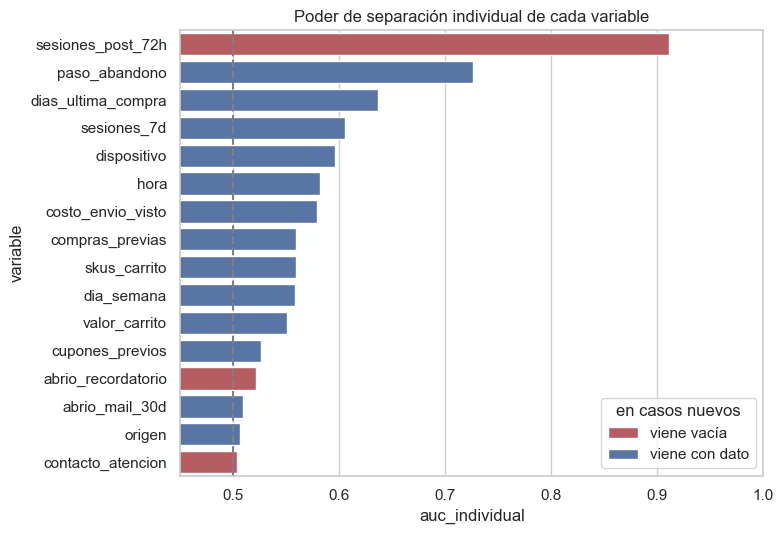

In [12]:
VARIABLES = [
    "compras_previas", "dias_ultima_compra", "valor_carrito", "skus_carrito", "paso_abandono",
    "costo_envio_visto", "dispositivo", "abrio_mail_30d", "origen", "sesiones_7d", "cupones_previos",
    "hora", "dia_semana",
    "sesiones_post_72h", "abrio_recordatorio", "contacto_atencion",
]

filas = []
for col in VARIABLES:
    filas.append({
        "variable": col,
        "auc_individual": auc_individual(historico, col, "no_volvio"),
        "% con dato en casos nuevos": nuevos[col].notna().mean() * 100,
    })
poder = pd.DataFrame(filas).sort_values("auc_individual", ascending=False).reset_index(drop=True)
poder["en casos nuevos"] = np.where(poder["% con dato en casos nuevos"] > 0, "viene con dato", "viene vacía")
display(poder.round(2))

fig, ax = plt.subplots(figsize=(8, 5.5))
colores = {"viene con dato": "#4C72B0", "viene vacía": "#C44E52"}
sns.barplot(data=poder, y="variable", x="auc_individual", hue="en casos nuevos", palette=colores, dodge=False, ax=ax)
ax.axvline(0.5, color="gray", linestyle="--")
ax.set_xlim(0.45, 1)
ax.set_title("Poder de separación individual de cada variable")
plt.tight_layout()
plt.show()

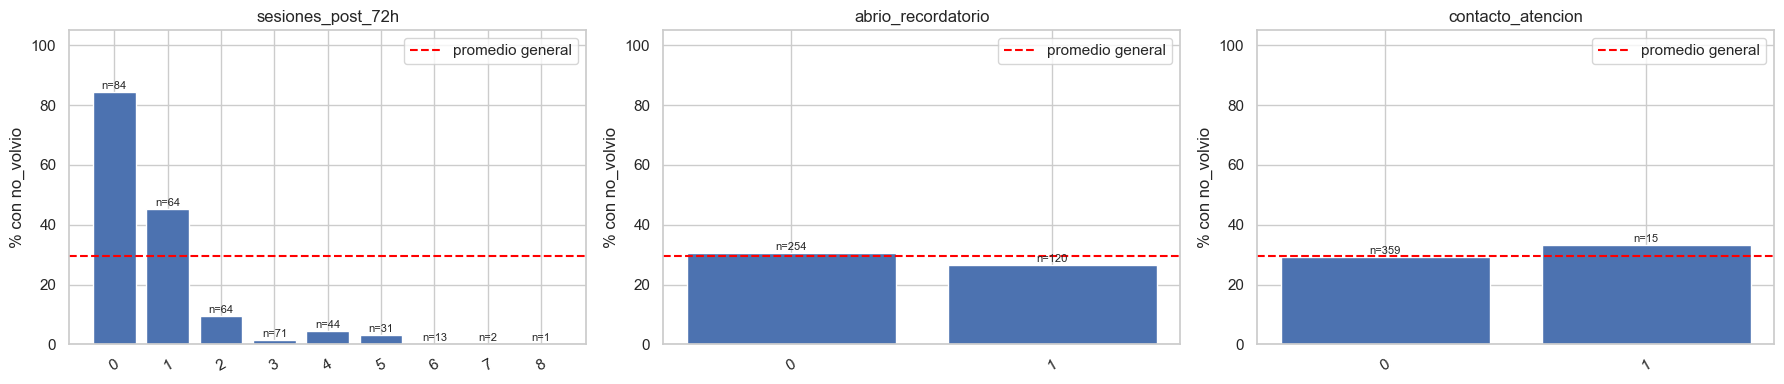

In [13]:
grilla_tasas(historico, ["sesiones_post_72h", "abrio_recordatorio", "contacto_atencion"], "no_volvio", ancho=6)

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué variable encabeza el ranking y está vacía en `casos_nuevos`? ¿Por qué un AUC altísimo no la hace útil? Fíjense en el momento en que se registra cada una (el mail recordatorio sale a las 24 horas): ¿existe al decidir? Armen la lista de variables que quedan afuera por este motivo._

### 2.5 Variable por variable: % de clientes que no vuelven

Una variable a la vez. Cada barra es el % de clientes que no volvieron dentro de esa categoría; el **n** indica cuántos carritos hay. Primero las variables de negocio más obvias (dónde abandonó, desde qué), después el comportamiento del cliente.

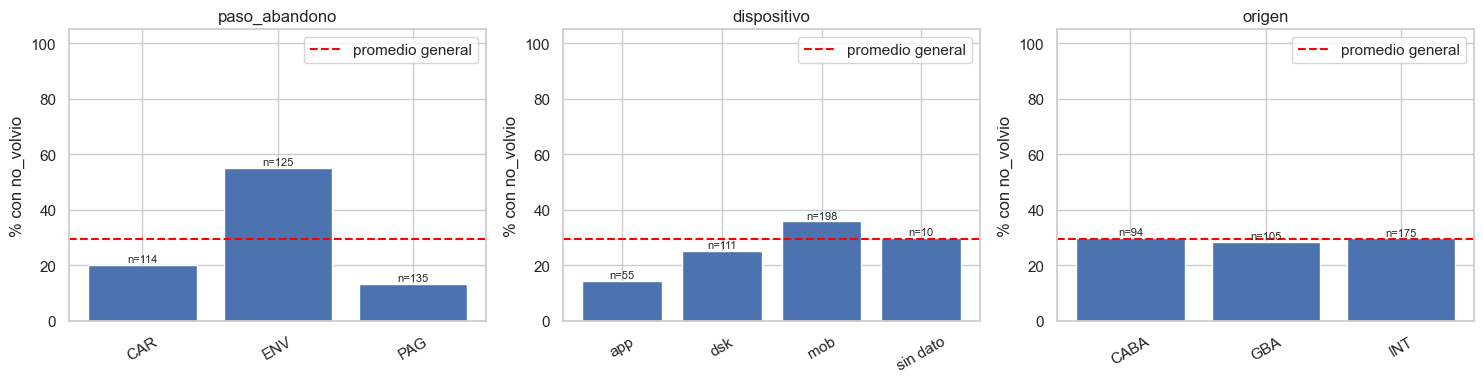

In [14]:
grilla_tasas(historico, ["paso_abandono", "dispositivo", "origen"], "no_volvio")

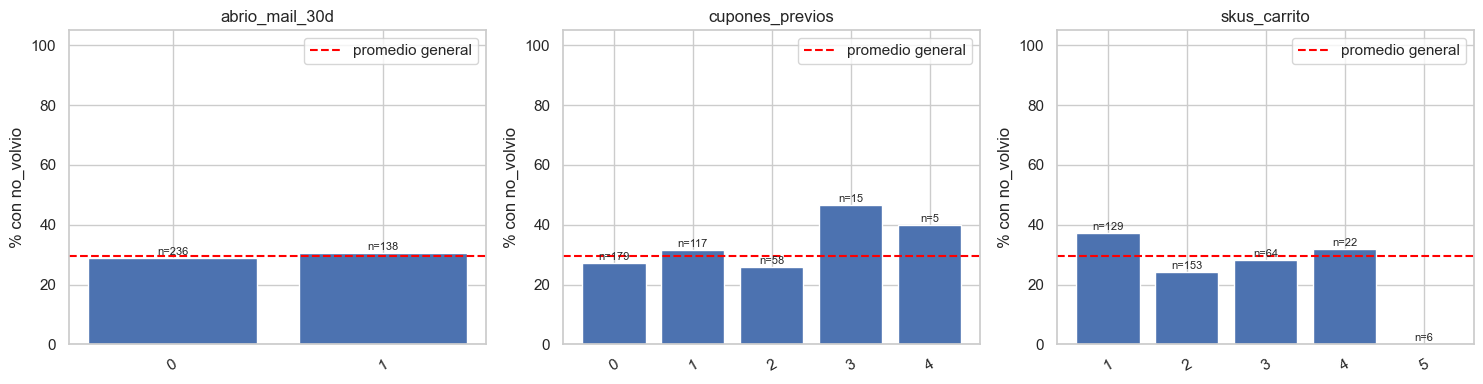

In [15]:
grilla_tasas(historico, ["abrio_mail_30d", "cupones_previos", "skus_carrito"], "no_volvio")

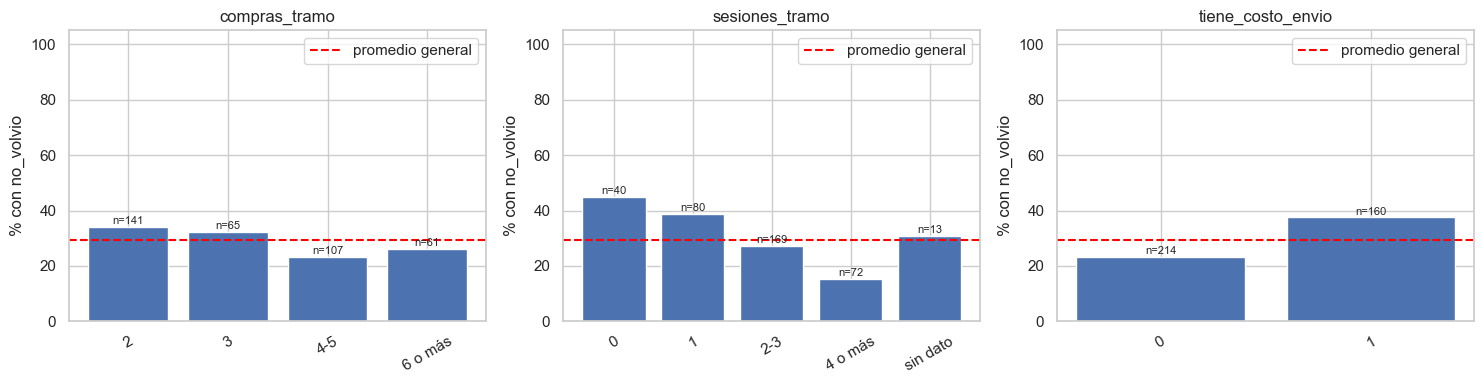

In [16]:
grilla_tasas(historico, ["compras_tramo", "sesiones_tramo", "tiene_costo_envio"], "no_volvio")

Además del **porcentaje**, importa dónde está el **volumen**: un paso con tasa altísima pero pocos carritos aporta pocos clientes perdidos. Esta tabla compara qué parte de los carritos y qué parte de los clientes que no vuelven aporta cada paso.

In [17]:
pareto = historico.groupby("paso_abandono", observed=True)["no_volvio"].agg(carritos="count", no_vuelven="sum", tasa="mean")
pareto["tasa_%"] = pareto["tasa"] * 100
pareto["% de los carritos"] = pareto["carritos"] / pareto["carritos"].sum() * 100
pareto["% de los que no vuelven"] = pareto["no_vuelven"] / pareto["no_vuelven"].sum() * 100
pareto.drop(columns="tasa").sort_values("% de los que no vuelven", ascending=False).round(1)

,carritos,no_vuelven,tasa_%,% de los carritos,% de los que no vuelven
paso_abandono,,,,,
ENV,125,69,55.2,33.4,62.7
CAR,114,23,20.2,30.5,20.9
PAG,135,18,13.3,36.1,16.4


**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué categorías se despegan claramente del promedio y con qué n? ¿Alguna diferencia podría ser ruido por tener pocos casos? ¿Hay variables que esperaban que importaran y no mueven nada (por ejemplo, el origen o la apertura de mails)? ¿Hay alguna que se comporte distinto a lo que decía la intuición?_

### 2.6 Variables continuas: días desde la última compra y valor del carrito

Ambas son continuas y tienen valores extremos (lo vimos en 2.2). Las agrupamos en **tramos** para que un valor como 2.000 días no distorsione el gráfico: el último tramo de `dias_ultima_compra` agrupa todo lo que pasa de 120, sea 130 o 2.000. Para el valor del carrito usamos **quintiles**: cinco grupos con la misma cantidad de carritos.

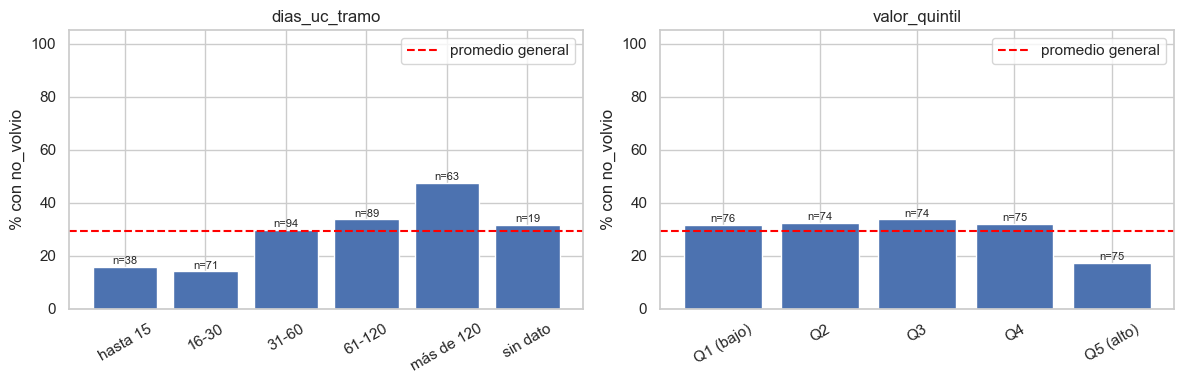

In [18]:
grilla_tasas(historico, ["dias_uc_tramo", "valor_quintil"], "no_volvio", ancho=6)

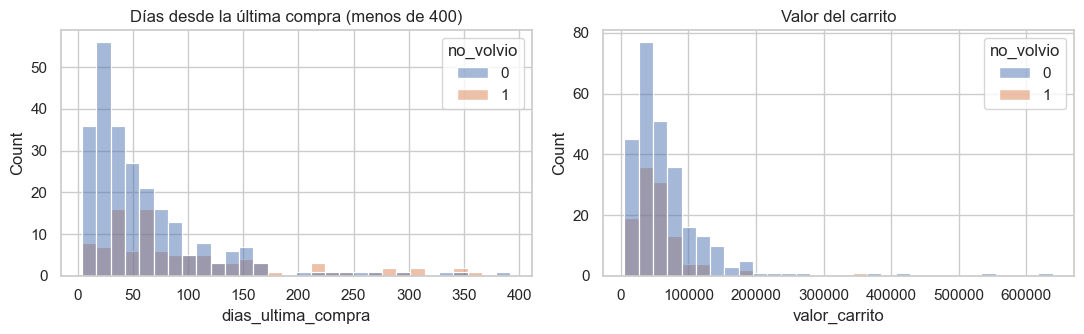

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(data=historico[historico["dias_ultima_compra"] < 400], x="dias_ultima_compra", hue="no_volvio", bins=30, ax=axes[0])
axes[0].set_title("Días desde la última compra (menos de 400)")
sns.histplot(data=historico, x="valor_carrito", hue="no_volvio", bins=30, ax=axes[1])
axes[1].set_title("Valor del carrito")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿el riesgo crece o decrece de forma ordenada con el tiempo desde la última compra? ¿Y con el valor del carrito? ¿Qué explicación de negocio le encuentran a cada una? ¿Qué pasa con los casos de más de 400 días?_

### 2.7 Cuándo se abandona

El momento del abandono existe al decidir, así que es información válida. Probamos el día de la semana, la franja horaria, la combinación de ambos y la evolución semanal (por si el problema empeora o mejora con el tiempo).

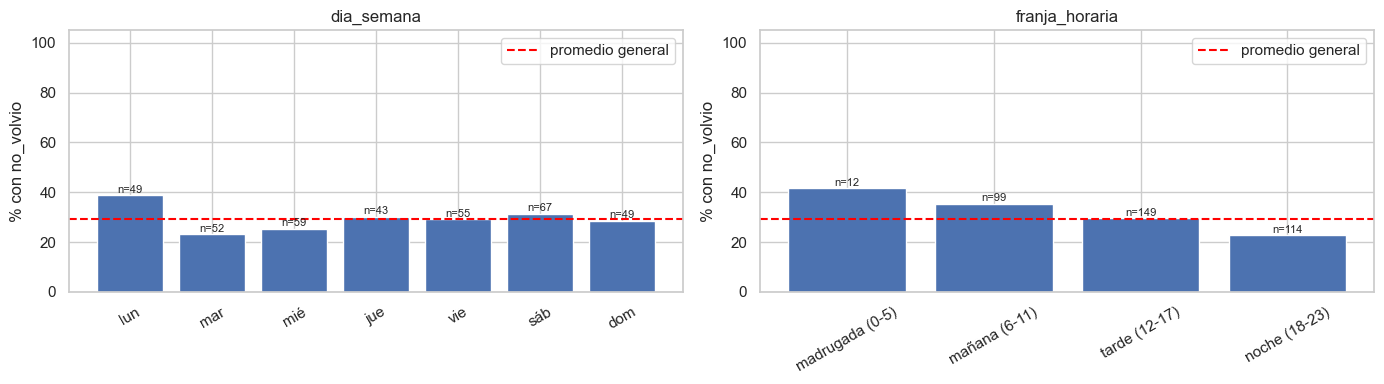

In [20]:
grilla_tasas(historico, ["dia_semana", "franja_horaria"], "no_volvio", ancho=7)

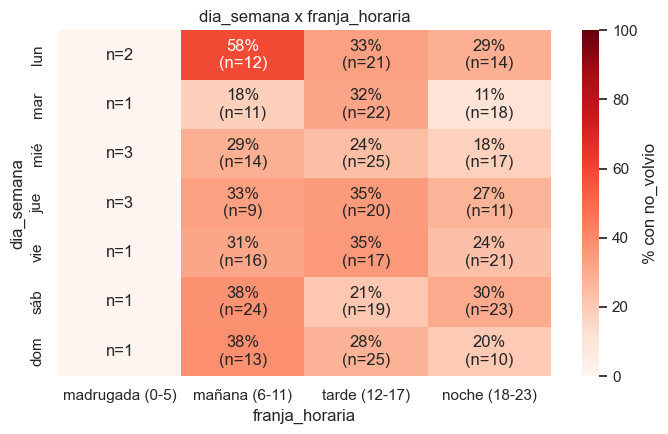

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
mapa_tasa(historico, "dia_semana", "franja_horaria", "no_volvio", ax)
plt.tight_layout()
plt.show()

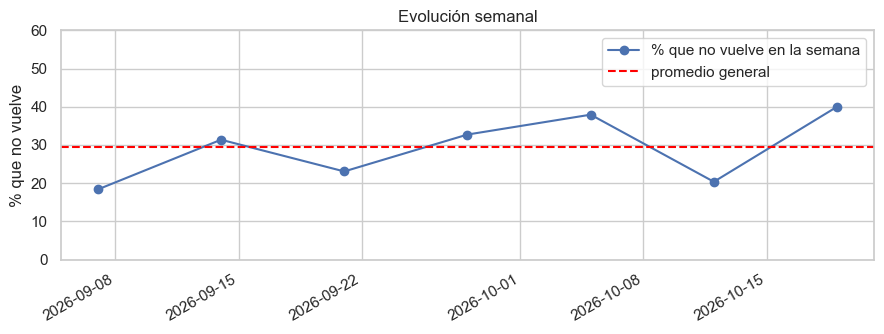

In [22]:
semanal = historico.groupby(historico["fecha_abandono"].dt.to_period("W").dt.start_time)["no_volvio"].agg(tasa="mean", n="count")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(semanal.index, semanal["tasa"] * 100, marker="o", label="% que no vuelve en la semana")
ax.axhline(historico["no_volvio"].mean() * 100, color="red", linestyle="--", label="promedio general")
ax.set_ylabel("% que no vuelve")
ax.set_ylim(0, 60)
ax.set_title("Evolución semanal")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿hay franjas u horarios con más abandono definitivo? ¿Hay un patrón claro o las barras bailan sin orden (cuidado con los n)? ¿Hay una tendencia a lo largo de las semanas?_

### 2.8 Combinaciones de variables

Los efectos suelen aparecer **combinados**: una variable pesa o no según el valor de otra. Los mapas de calor muestran el % de clientes que no vuelven por cruce. Las celdas con menos de 5 carritos se dejan sin color (solo se muestra el n), para no sacar conclusiones de muestras diminutas.

Esto además anticipa por qué vamos a usar modelos de árboles: capturan interacciones solos, sin que nosotros las armemos a mano (en regresión lineal sí había que crearlas).

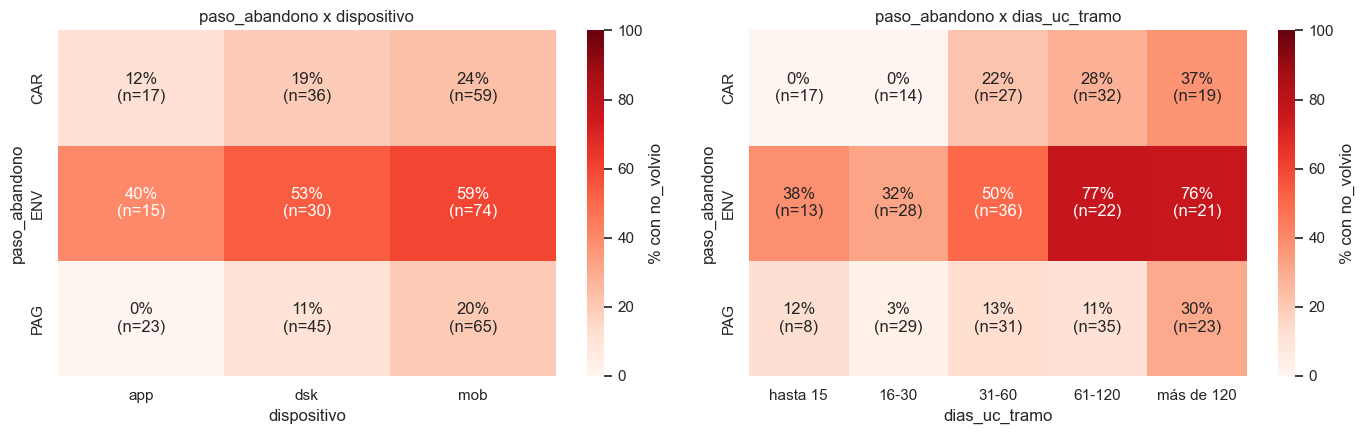

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
mapa_tasa(historico, "paso_abandono", "dispositivo", "no_volvio", axes[0])
mapa_tasa(historico, "paso_abandono", "dias_uc_tramo", "no_volvio", axes[1])
plt.tight_layout()
plt.show()

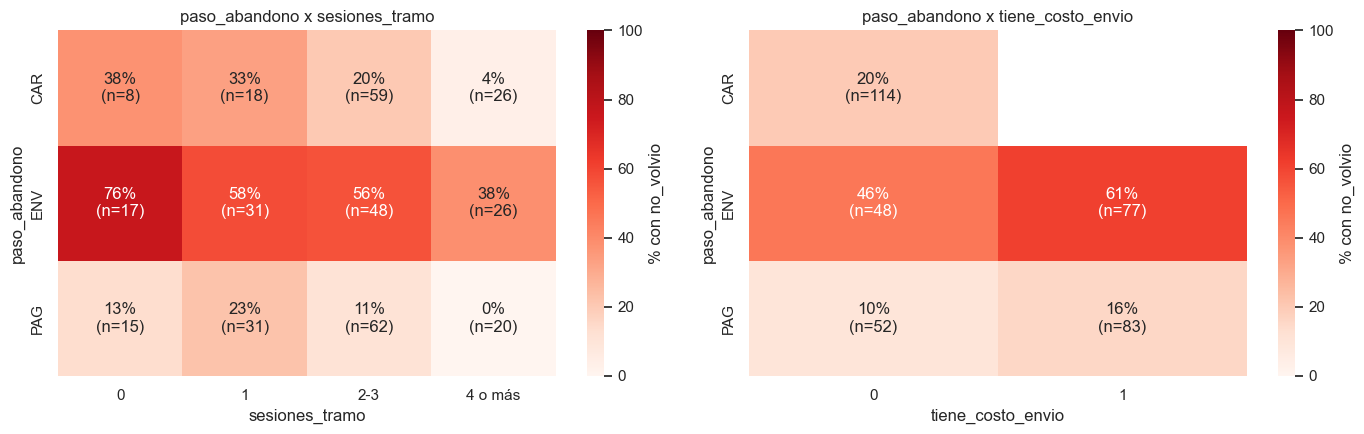

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
mapa_tasa(historico, "paso_abandono", "sesiones_tramo", "no_volvio", axes[0])
mapa_tasa(historico, "paso_abandono", "tiene_costo_envio", "no_volvio", axes[1])
plt.tight_layout()
plt.show()

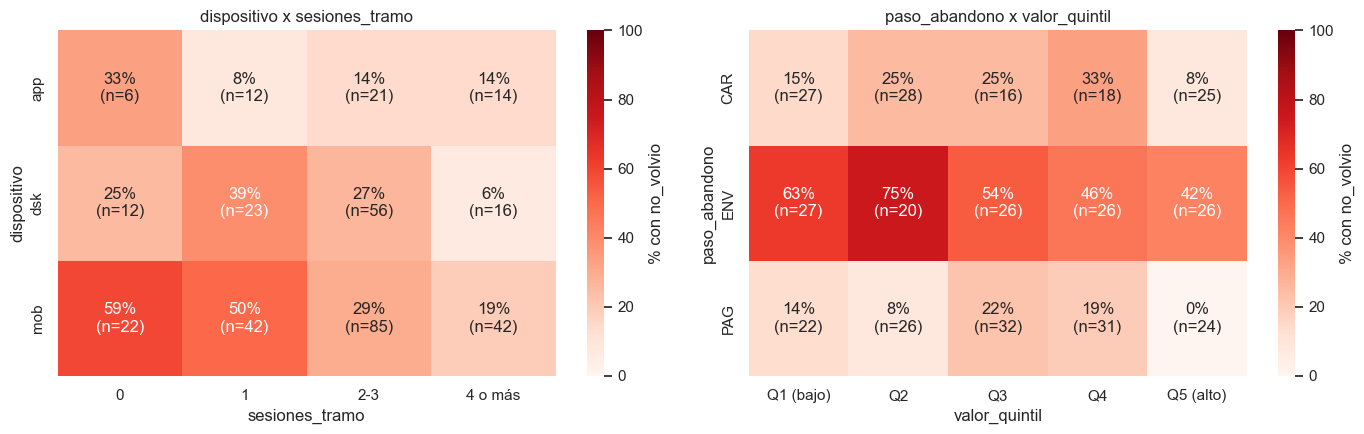

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
mapa_tasa(historico, "dispositivo", "sesiones_tramo", "no_volvio", axes[0])
mapa_tasa(historico, "paso_abandono", "valor_quintil", "no_volvio", axes[1])
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿el efecto del paso de abandono es parejo en todos los dispositivos y tramos de recencia, o hay combinaciones extremas? ¿Ver el costo de envío empeora el abandono en todos los pasos? Mirando el caso de más riesgo, ¿qué historia de negocio cuenta (qué le pasó a ese cliente)? ¿Qué combinaciones son de riesgo alto con n suficiente?_

### 2.9 Correlaciones

Resumen rápido de la relación lineal de cada variable numérica con que el cliente no vuelva. Es útil como panorama, pero tiene un límite: la correlación solo detecta relaciones que van "siempre para el mismo lado". Comparenlo con lo que ya vieron en los gráficos de 2.5 a 2.8.

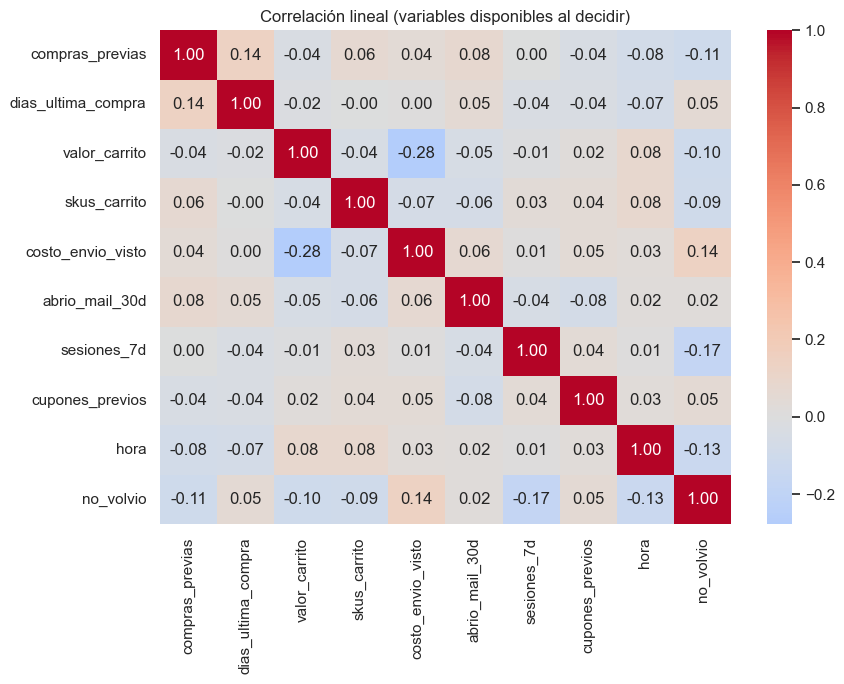

In [26]:
numericas = ["compras_previas", "dias_ultima_compra", "valor_carrito", "skus_carrito", "costo_envio_visto",
             "abrio_mail_30d", "sesiones_7d", "cupones_previos", "hora", "no_volvio"]

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(historico[numericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación lineal (variables disponibles al decidir)")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué variables tienen correlación visible con `no_volvio`? ¿Hay patrones fuertes en los gráficos anteriores que acá NO aparecen? ¿Por qué? (pista: piensen en el paso de abandono, que es una categoría)_

### 2.10 Dónde se concentra el problema

Para decidir a quién le mandamos el cupón nos sirve conocer los segmentos de **riesgo alto con volumen suficiente**. Esta tabla cruza paso de abandono y dispositivo (solo grupos de 10 carritos o más) y muestra cuántos clientes que no vuelven aporta cada uno al total.

In [27]:
segmentos = historico.groupby(["paso_abandono", "dispositivo"], observed=True)["no_volvio"].agg(carritos="count", no_vuelven="sum", tasa="mean")
segmentos["tasa_%"] = segmentos["tasa"] * 100
segmentos["% del total que no vuelve"] = segmentos["no_vuelven"] / historico["no_volvio"].sum() * 100
segmentos = segmentos[segmentos["carritos"] >= 10].drop(columns="tasa")

print("Mayor tasa de no retorno:")
display(segmentos.sort_values("tasa_%", ascending=False).head(8).round(1))
print("Mayor aporte al total de clientes que no vuelven:")
display(segmentos.sort_values("no_vuelven", ascending=False).head(8).round(1))

Mayor tasa de no retorno:


carritos  no_vuelven  tasa_%  \
paso_abandono dispositivo                                 
ENV           mob                74          44    59.5   
              dsk                30          16    53.3   
              app                15           6    40.0   
CAR           mob                59          14    23.7   
PAG           mob                65          13    20.0   
CAR           dsk                36           7    19.4   
              app                17           2    11.8   
PAG           dsk                45           5    11.1   

                           % del total que no vuelve  
paso_abandono dispositivo                             
ENV           mob                               40.0  
              dsk                               14.5  
              app                                5.5  
CAR           mob                               12.7  
PAG           mob                               11.8  
CAR           dsk                                6.4  
              app                                1.8  
PAG           dsk                                4.5

Mayor aporte al total de clientes que no vuelven:


carritos  no_vuelven  tasa_%  \
paso_abandono dispositivo                                 
ENV           mob                74          44    59.5   
              dsk                30          16    53.3   
CAR           mob                59          14    23.7   
PAG           mob                65          13    20.0   
CAR           dsk                36           7    19.4   
ENV           app                15           6    40.0   
PAG           dsk                45           5    11.1   
CAR           app                17           2    11.8   

                           % del total que no vuelve  
paso_abandono dispositivo                             
ENV           mob                               40.0  
              dsk                               14.5  
CAR           mob                               12.7  
PAG           mob                               11.8  
CAR           dsk                                6.4  
ENV           app                                5.5  
PAG           dsk                                4.5  
CAR           app                                1.8

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿los segmentos de mayor tasa son los mismos que más clientes aportan? Si el cupo es de 90 cupones, ¿conviene priorizar por segmento o por la probabilidad individual de cada cliente?_

### 2.11 ¿Qué diferencias son reales? Intervalos de confianza

En 2.5 vimos barras con su n, pero un porcentaje calculado sobre 30 casos es mucho más incierto que uno calculado sobre 300. Acá cada punto es la tasa observada y la línea es el **intervalo de confianza del 95%**: el rango donde probablemente está la tasa verdadera.

Regla práctica: si el intervalo de un grupo **no toca** la línea roja del promedio general, la diferencia probablemente no es casualidad. Si la toca, o se superpone con el de otros grupos, cuidado con sacar conclusiones.

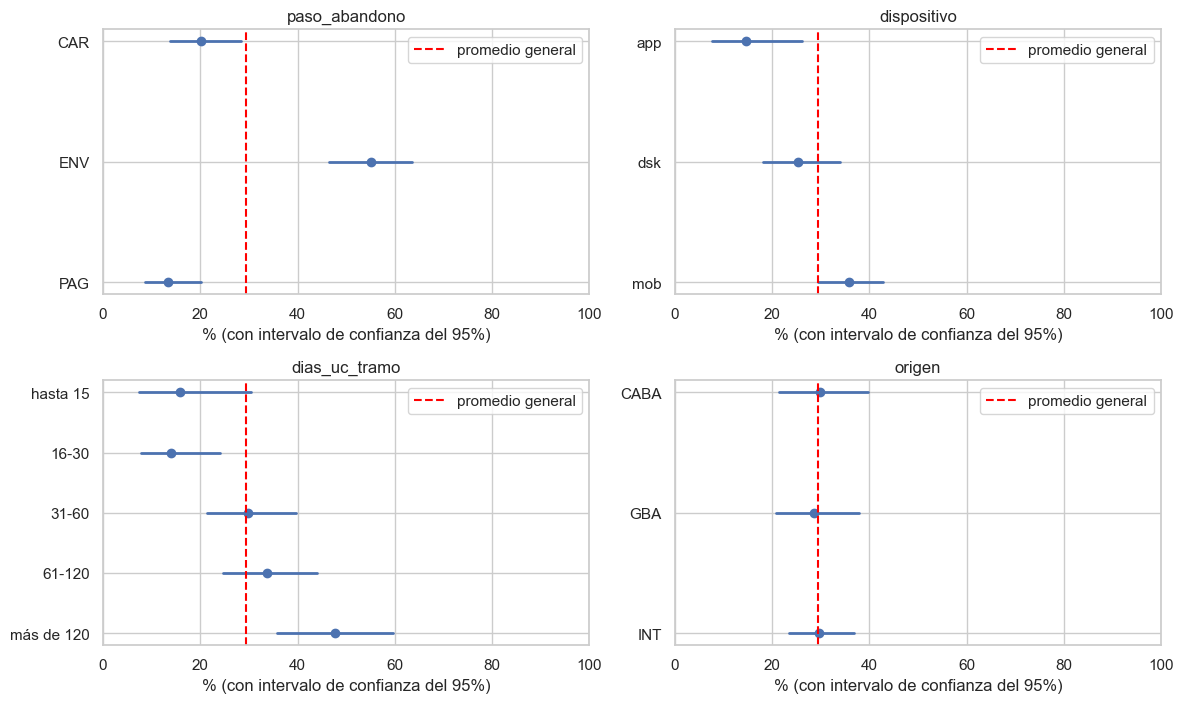

In [28]:
grilla_intervalos(historico, ["paso_abandono", "dispositivo", "dias_uc_tramo", "origen"], "no_volvio")

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué diferencias de 2.5 aguantan el intervalo y cuáles se desarman? ¿Qué categorías tienen un intervalo tan ancho que no se puede decir nada? ¿Qué pasa con el origen y con la apertura de mails: ¿hay diferencias o son todos indistinguibles?_

### 2.12 Curvas de riesgo para variables continuas

Las variables continuas se leen mejor como **curva** que como barras. Dividimos los casos en 8 grupos de igual tamaño, ubicamos cada grupo en su mediana y marcamos el intervalo de confianza.

Sirve para distinguir si la relación es creciente, decreciente, escalonada o inexistente, y para ver si hay un **punto de quiebre**. Esos puntos son justamente donde un árbol decide cortar.

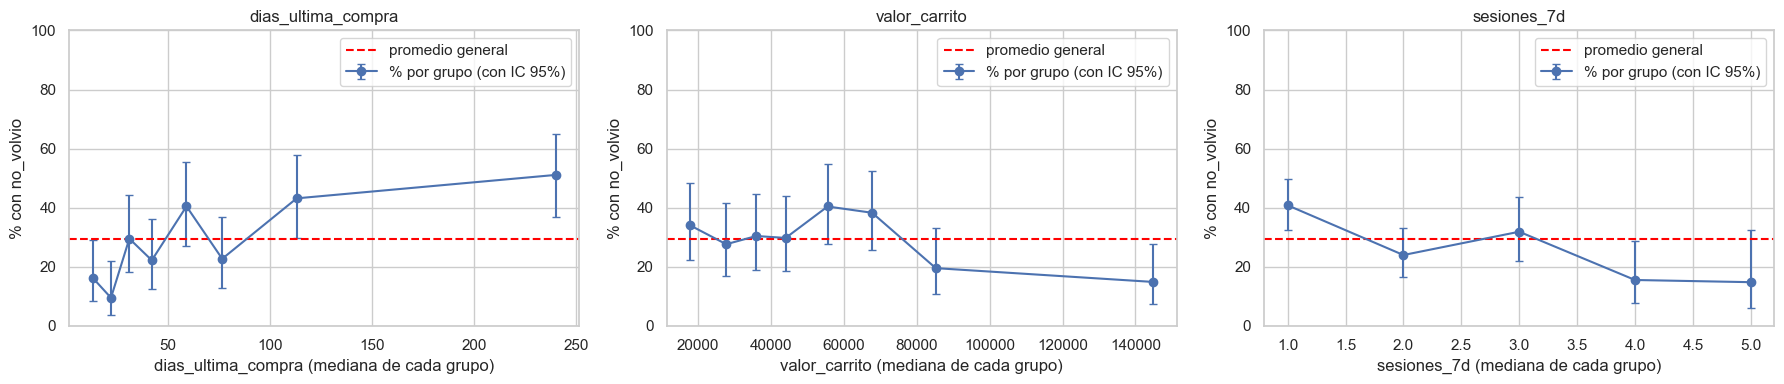

In [29]:
grilla_curvas(historico, ["dias_ultima_compra", "valor_carrito", "sesiones_7d"], "no_volvio")

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿la curva sube, baja, se mueve a escalones o es plana? ¿Hay un punto donde el riesgo cambia de nivel? ¿Los intervalos dejan afirmar que hay una tendencia?_

### 2.13 Volumen contra riesgo

Dos formas de ver dónde está la plata. El **gráfico de burbujas** ubica cada segmento según su cantidad de casos (eje horizontal) y su tasa de riesgo (eje vertical); el tamaño de la burbuja es cuántos casos positivos aporta. El **gráfico de barras** compara qué parte de los casos y qué parte de los positivos aporta cada grupo.

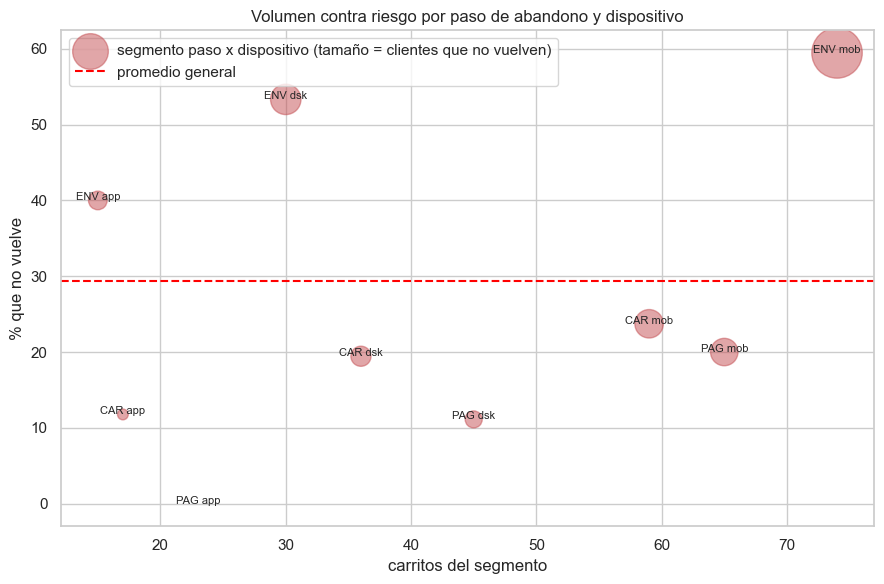

In [30]:
seg = historico.groupby(["paso_abandono", "dispositivo"], observed=True)["no_volvio"].agg(carritos="count", no_vuelven="sum", tasa="mean").reset_index()
seg["segmento"] = seg["paso_abandono"].astype(str) + " " + seg["dispositivo"].astype(str)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(seg["carritos"], seg["tasa"] * 100, s=seg["no_vuelven"] * 30, alpha=0.5, color="#C44E52",
           label="segmento paso x dispositivo (tamaño = clientes que no vuelven)")
for i in range(len(seg)):
    ax.annotate(seg["segmento"].iloc[i], (seg["carritos"].iloc[i], seg["tasa"].iloc[i] * 100), fontsize=8, ha="center")
ax.axhline(historico["no_volvio"].mean() * 100, color="red", linestyle="--", label="promedio general")
ax.set_xlabel("carritos del segmento")
ax.set_ylabel("% que no vuelve")
ax.set_title("Volumen contra riesgo por paso de abandono y dispositivo")
ax.legend()
plt.tight_layout()
plt.show()

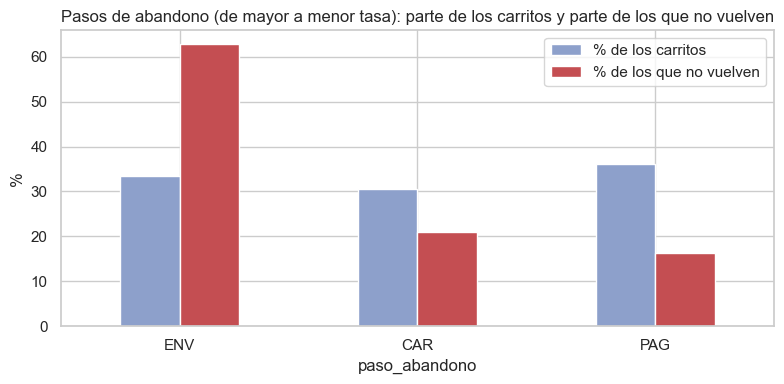

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
barras = pareto.sort_values("tasa_%", ascending=False)[["% de los carritos", "% de los que no vuelven"]]
barras.plot(kind="bar", ax=ax, color=["#8DA0CB", "#C44E52"])
ax.set_ylabel("%")
ax.set_title("Pasos de abandono (de mayor a menor tasa): parte de los carritos y parte de los que no vuelven")
ax.tick_params(axis="x", labelrotation=0)
ax.legend()
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué segmentos están arriba y a la derecha (riesgo alto y mucho volumen)? ¿Hay segmentos de riesgo altísimo pero tan chicos que mueven poco la plata? ¿Qué grupos aportan más positivos de los que les corresponderían por su tamaño?_

### 2.14 Qué ve un árbol chico

Para pasar del "hay patrones" al "estas son las reglas", entrenamos un **árbol de decisión de profundidad 3** con las variables disponibles al decidir, **solo para leerlo**. No es el modelo del desafío (eso es la sección 4).

Cada caja muestra la regla de corte, cuántos casos caen ahí (`samples`), cuántos son de cada clase (`value`, en el orden [volvió, no volvió]) y la clase mayoritaria. El color indica la clase mayoritaria (naranja una, azul la otra) y cuanto más intenso, más "puro" es el grupo. Si la condición de la caja se cumple, el camino va por la izquierda (`True`). Como las variables categóricas se abren en variables 0/1, una caja que dice `paso_abandono_ENV <= 0.5` separa lo que **no** cumple esa condición (izquierda) de lo que sí (derecha). `dia_semana_n` va de 0 (lunes) a 6 (domingo).

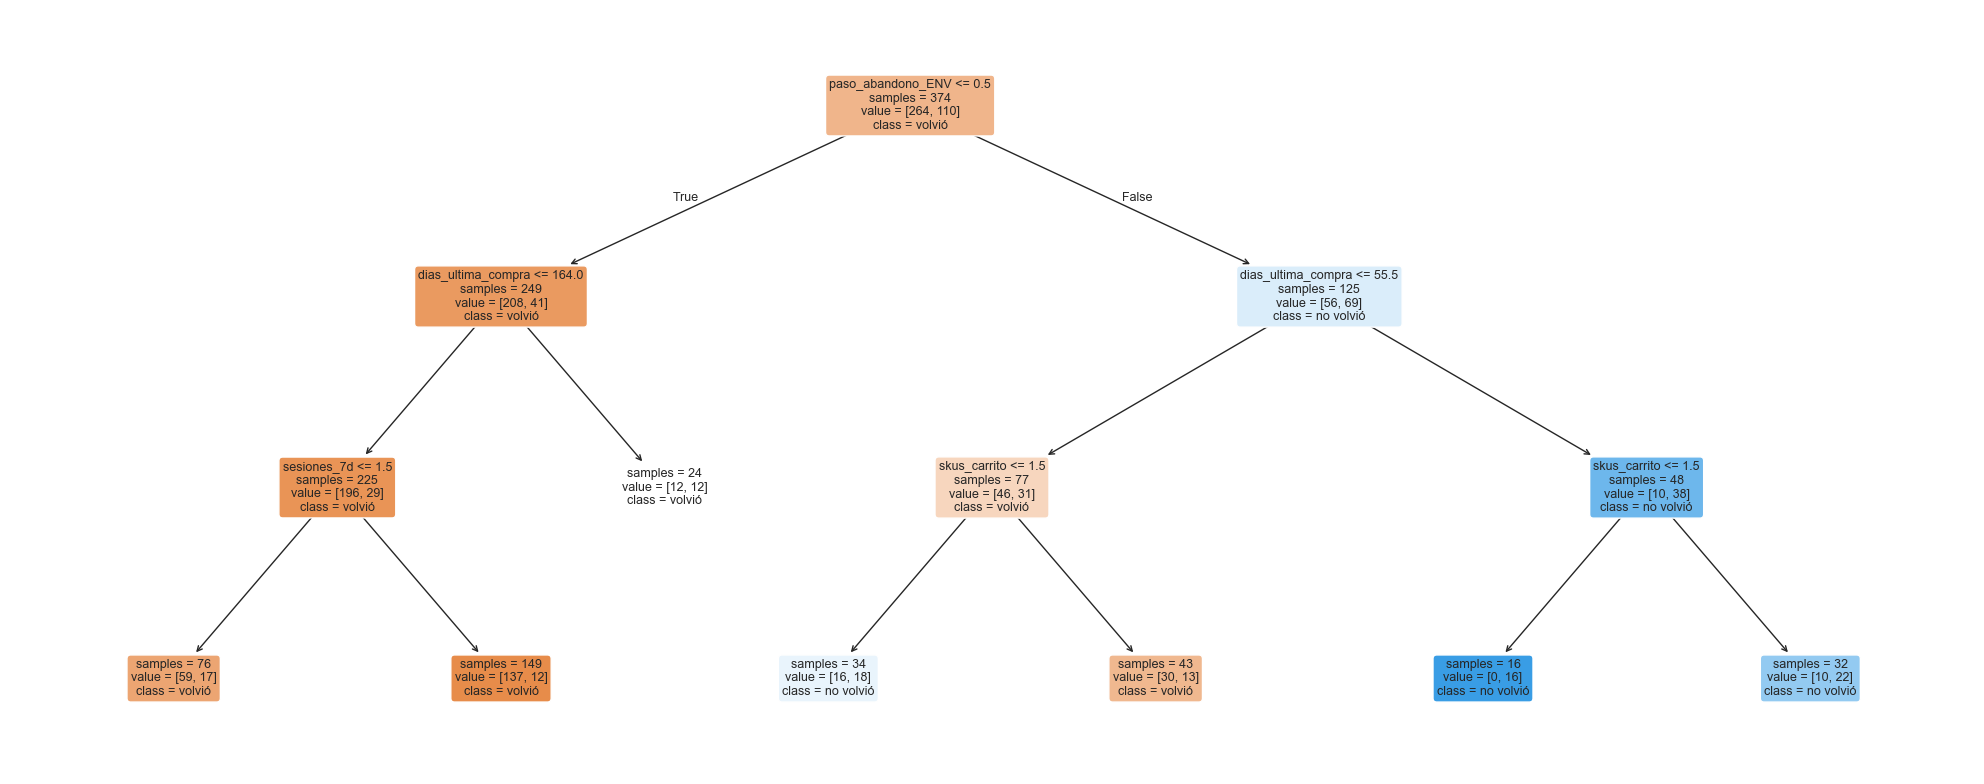

In [32]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

VARIABLES_ARBOL = ["paso_abandono", "dispositivo", "origen", "compras_previas", "dias_ultima_compra", "valor_carrito", "skus_carrito", "costo_envio_visto", "abrio_mail_30d", "sesiones_7d", "cupones_previos", "hora"]
CATEGORICAS = ["paso_abandono", "dispositivo", "origen"]

X = historico[VARIABLES_ARBOL].copy()
X["dia_semana_n"] = historico["fecha_abandono"].dt.dayofweek  # 0 = lunes, 6 = domingo
X = pd.get_dummies(X, columns=CATEGORICAS, dtype=float).fillna(-1)  # -1 marca el dato faltante, solo para esta exploración
y = historico["no_volvio"]

arbol = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=SEED)
arbol.fit(X, y)

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(arbol, feature_names=list(X.columns), class_names=["volvió", "no volvió"],
          filled=True, impurity=False, rounded=True, fontsize=9, ax=ax)
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿qué variable usa el árbol para la primera pregunta y coincide con lo que encontraron? ¿Qué hoja concentra más riesgo y qué historia de negocio cuenta? ¿Aparece alguna variable que habían descartado en el EDA?_

### 2.15 ¿Cuánto vale priorizar bien?

Último paso: medir cuánto aporta una regla de priorización respecto de no hacer nada.

La **curva de captura** ordena los casos de mayor a menor riesgo y muestra qué porcentaje de los positivos se captura al ir cubriendo cada vez más casos. Se compara con el azar (la diagonal) y con el orden perfecto (el techo). Las probabilidades salen de un árbol chico evaluado con **validación cruzada**, para no premiarlo por casos que ya vio.

AUC de la regla simple (validación cruzada de 5 folds): 0.74


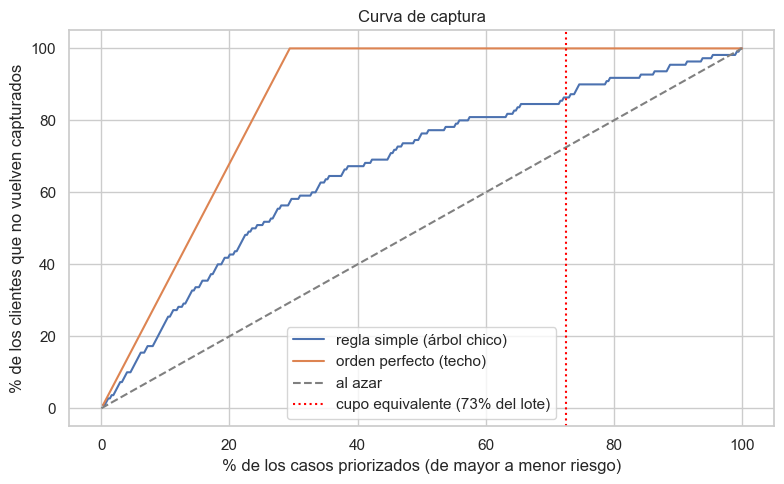

Priorizando el 73% de los casos, la regla captura el 86% de los clientes que no vuelven (al azar capturaría el 73%).


In [33]:
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import StratifiedKFold, cross_val_predict


def orden_por_puntaje(puntaje):
    # ordena de mayor a menor puntaje; los empates se desempatan al azar (con semilla fija)
    ruido = np.random.default_rng(SEED).uniform(0, 1e-6, len(puntaje))
    return np.argsort(-(puntaje + ruido))


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
arbol_chico = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=SEED)
prob = cross_val_predict(arbol_chico, X, y, cv=cv, method="predict_proba")[:, 1]
print(f"AUC de la regla simple (validación cruzada de 5 folds): {roc_auc_score(y, prob):.2f}")

y_np = y.to_numpy()
total_pos = y_np.sum()
n_casos = len(y_np)
x = np.arange(1, n_casos + 1) / n_casos * 100
capturados = np.cumsum(y_np[orden_por_puntaje(prob)]) / total_pos * 100
techo = np.minimum(np.arange(1, n_casos + 1), total_pos) / total_pos * 100
pct_cupo = CUPO / N_NUEVOS * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, capturados, label="regla simple (árbol chico)")
ax.plot(x, techo, label="orden perfecto (techo)")
ax.plot([0, 100], [0, 100], linestyle="--", color="gray", label="al azar")
ax.axvline(pct_cupo, color="red", linestyle=":", label=f"cupo equivalente ({pct_cupo:.0f}% del lote)")
ax.set_xlabel("% de los casos priorizados (de mayor a menor riesgo)")
ax.set_ylabel("% de los clientes que no vuelven capturados")
ax.set_title("Curva de captura")
ax.legend()
plt.tight_layout()
plt.show()

captura_en_cupo = np.interp(pct_cupo, x, capturados)
print(f"Priorizando el {pct_cupo:.0f}% de los casos, la regla captura el {captura_en_cupo:.0f}% de los clientes que no vuelven (al azar capturaría el {pct_cupo:.0f}%).")

Ahora lo traducimos a plata. Comparamos el costo esperado de un lote bajo distintas reglas, siempre respetando el cupo salvo en la barra que dice "ignorando":

Supuesto: el cupón recupera a todo cliente que no iba a volver (según el metadata) y lo usa cualquiera que lo reciba, así que cada cupón enviado cuesta $1.500; un cliente que no vuelve y no recibió cupón cuesta $9.000 de margen. El costo se expresa **por lote nuevo** (124 carritos).

Esto es una **vara a superar**, no la solución. Acá el ordenamiento sale de un árbol de profundidad 3 y no hay un umbral. Qué tan lejos se puede llegar con Random Forest y XGBoost, y cómo se convierte la probabilidad en decisión, es el trabajo de las secciones 4 y 5.

,costo por lote,ahorro vs no hacer nada
"Orden perfecto, hasta el cupo (techo)",$134.775,$193.460
"Una sola variable (paso_abandono), hasta el cupo",$179.535,$148.701
"Árbol chico, hasta el cupo",$179.535,$148.701
Cupón a todos (ignorando el tope),$186.000,$142.235
"Al azar, hasta el cupo",$225.172,$103.064
No hacer nada,$328.235,$0


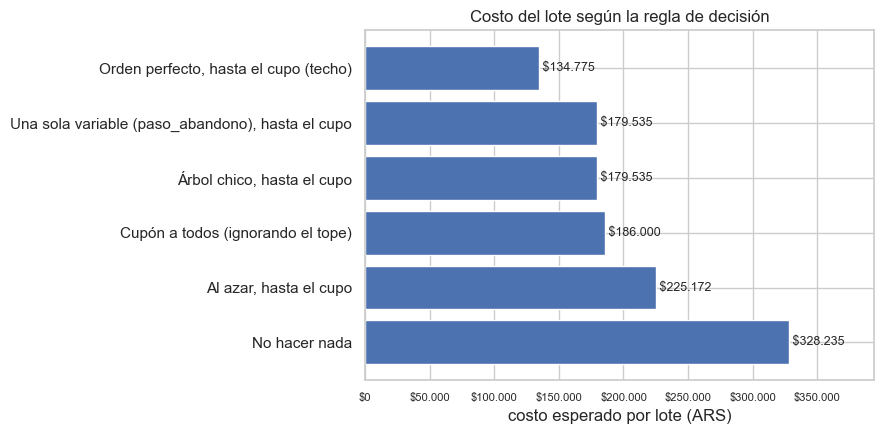

In [34]:
COSTO_ACCION = DESCUENTO_CUPON    # lo que cuesta actuar sobre un caso
COSTO_PERDIDA = MARGEN_PERDIDO   # lo que cuesta un caso positivo que no cubrimos
escala = N_NUEVOS / N_HIST           # para expresar todo por lote nuevo
K = round(CUPO / N_NUEVOS * N_HIST)  # cupo equivalente en el tamaño del histórico


def costo_total(elegidos):
    cubiertos = y_np[elegidos].sum()
    return (len(elegidos) * COSTO_ACCION + (total_pos - cubiertos) * COSTO_PERDIDA) * escala


puntaje_regla = historico["paso_abandono"].map(historico.groupby("paso_abandono")["no_volvio"].mean()).to_numpy()
orden_regla = orden_por_puntaje(puntaje_regla)
orden_arbol = orden_por_puntaje(prob)
orden_techo = np.argsort(-y_np, kind="stable")

costos = {
    "No hacer nada": total_pos * COSTO_PERDIDA * escala,
    "Cupón a todos (ignorando el tope)": costo_total(np.arange(n_casos)),
    "Al azar, hasta el cupo": (K * COSTO_ACCION + (total_pos - K * y_np.mean()) * COSTO_PERDIDA) * escala,
    "Una sola variable (paso_abandono), hasta el cupo": costo_total(orden_regla[:K]),
    "Árbol chico, hasta el cupo": costo_total(orden_arbol[:K]),
    "Orden perfecto, hasta el cupo (techo)": costo_total(orden_techo[:K]),
}
tabla = pd.DataFrame({"costo por lote": pd.Series(costos)}).sort_values("costo por lote")
tabla["ahorro vs no hacer nada"] = costos["No hacer nada"] - tabla["costo por lote"]

mostrar = tabla.copy()
for col in mostrar.columns:
    mostrar[col] = mostrar[col].apply(pesos)
display(mostrar)

def formato_pesos(valor, posicion):
    return pesos(valor)


fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(tabla.index, tabla["costo por lote"], color="#4C72B0")
ax.xaxis.set_major_formatter(FuncFormatter(formato_pesos))
ax.tick_params(axis="x", labelsize=8)
for i in range(len(tabla)):
    ax.text(tabla["costo por lote"].iloc[i], i, " " + pesos(tabla["costo por lote"].iloc[i]), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, tabla["costo por lote"].max() * 1.2)
ax.set_xlabel("costo esperado por lote (ARS)")
ax.set_title("Costo del lote según la regla de decisión")
plt.tight_layout()
plt.show()

**Qué veo:** _(completar: qué patrón aparece, con qué número, y si cambia la decisión)_

_Preguntas guía: ¿Por qué las reglas simples se parecen tanto entre sí cuando el cupo cubre casi todo el lote? ¿Qué distingue a este problema del de elegir pocos casos entre muchos? ¿Qué pasa si mandamos cupón a todos, ignorando el tope? ¿Cuánto separa a las reglas del techo y qué creen que explica esa distancia?_

### 2.16 Síntesis del EDA

Cierren el EDA con lo que van a llevar a las slides. Mínimo **2 insights**, cada uno con las tres partes, y **uno que no esperaban**.

**Insight 1**
- Qué encontramos: _..._
- Evidencia (número): _..._
- Qué implica para la decisión: _..._

**Insight 2**
- Qué encontramos: _..._
- Evidencia (número): _..._
- Qué implica para la decisión: _..._

**Insight inesperado**
- Qué encontramos: _..._
- Evidencia (número): _..._
- Qué implica para la decisión: _..._

**Variables que usamos en el modelo** (y por qué): _..._

**Variables que descartamos** (y por qué: no están disponibles al decidir, son identificadores, no aportan señal, etc.): _..._

## 3. Preparación

**Stream B.** No hay limpieza de datos como tal (no llegan los tiempos), pero sí hay que dejar el dataset listo para los modelos.

- ¿Qué columnas categóricas hay que convertir a números? ¿Cómo?
- ¿Hay valores nulos en las variables que elegimos? ¿Qué hacemos con ellos?
- ¿Necesitamos escalar las variables? Pensá en lo que vimos con KNN (Clase 05) y comparalo con modelos de árboles.

In [35]:
# Separar X (variables elegidas) e y (target)


In [36]:
# Codificar categóricas


### Partición train / validación

Necesitamos una parte de los datos que el modelo **no vea** para evaluarlo con honestidad.

- ¿Qué proporción reservamos?
- ¿Hace falta `stratify`? Pensá en el porcentaje de positivos de `nv_72h` que calcularon en 2.1.

In [37]:
# train_test_split


In [38]:
# Chequear que la proporción del target se mantenga en ambos sets


## 4. Modelado

Se pide entrenar **dos modelos** (Random Forest y XGBoost), cada uno con GridSearch, y compararlos con las mismas reglas.

### 4.1 Elegir la métrica de evaluación

Antes de correr el GridSearch hay que decidir con qué métrica se elige el mejor modelo.

- ¿Sirve `accuracy` si los positivos son pocos? ¿Por qué?
- ¿Qué error es más caro para el negocio: marcar de más o dejar pasar un caso?
- ¿Qué métrica elegimos para `scoring` y por qué?

**Decisión:** _(métrica elegida y justificación de negocio)_

### 4.2 Random Forest + GridSearch

- ¿Qué hiperparámetros vamos a probar? ¿Por qué esos y no otros?
- ¿Cuántos folds de cross validation? ¿Cuántas combinaciones se evalúan en total, y cuánto tarda?

In [39]:
# Definir grilla y correr GridSearchCV para Random Forest


In [40]:
# Mejores hiperparámetros y mejor score en CV


### 4.3 XGBoost + GridSearch

Misma lógica que 4.2, con los hiperparámetros propios de XGBoost.

- ¿Qué cambia respecto del Random Forest en cómo construye los árboles? (Clase 08)

In [41]:
# Definir grilla y correr GridSearchCV para XGBoost


In [42]:
# Mejores hiperparámetros y mejor score en CV


### 4.4 Comparación

Los dos modelos se evalúan **sobre el set de validación**, con las mismas métricas.

- Reportar para cada uno: matriz de confusión, precision, recall, F1 y AUC.
- Curva ROC o Precision-Recall de los dos en un mismo gráfico.

In [43]:
# Métricas de Random Forest en validación


In [44]:
# Métricas de XGBoost en validación


In [45]:
# Tabla comparativa y curvas


**Modelo elegido:** _(cuál y por qué; si la diferencia es chica, ¿vale la pena la complejidad extra?)_

**Importancia de variables:** _(¿coincide con lo que encontramos en el EDA?)_

## 5. Umbral y decisión de negocio

Acá es donde el ejercicio se gana o se pierde. Un modelo con buen AUC no es una decisión: hay que convertir probabilidades en una acción, respetando costos y cupo.

Pensemos con los costos del metadata. Se asume que el cupón recupera a quien no iba a volver, y que lo puede usar cualquiera:

- Si le mandan el cupón a alguien que **no** iba a volver, ¿cuánto ganan? Si se lo mandan a alguien que **sí** iba a volver, ¿cuánto pierden? Escriban la ecuación de beneficio esperado en función de la probabilidad.
- ¿A partir de qué probabilidad de no volver conviene mandar el cupón? Hagan la cuenta en el notebook.
- Con ese umbral, ¿cuántos clientes del lote marcaría el modelo? ¿Entran en los 90 cupones?
- Si no entran, ¿a quiénes priorizamos? Si sobran, ¿los usamos igual?

In [46]:
# Probabilidades del modelo elegido sobre validación


In [47]:
# Costo total según umbral (curva de costo vs umbral)


In [48]:
# Costo total con la regla top-N por cupo


**Regla de decisión elegida:** _(umbral, top-N o combinación, y justificación en plata)_

**Comparación contra no hacer nada:** _(ahorro estimado por lote)_

## 6. Predicción sobre casos nuevos

Aplicamos el modelo elegido y la regla de decisión sobre `casos_nuevos.csv`.

- ¿Reentrenamos con **todo** el histórico o usamos el modelo ya entrenado? ¿Qué conviene y por qué?
- ¿Cuántos casos marcó el modelo como positivos del total?
- ¿A cuántos van a recibir el cupón finalmente, dado el cupo?

In [49]:
# Predecir probabilidades sobre casos_nuevos


In [50]:
# Aplicar la regla de decisión y contar positivos / total


In [51]:
# Lista final de casos elegidos


**Resultado:** _(X positivos sobre Y casos; Z elegidos para recibir el cupón)_

**Costo esperado del lote con la regla vs sin hacer nada:** _(estimación)_

## 7. Conclusión y slides

**Stream C.** Entre 2 y 4 slides. Cada una con un título que diga el insight (no el tema), un gráfico y una frase de cierre.

| Slide | Contenido |
|---|---|
| 1 | Insights del EDA (los 2 o 3 más fuertes, con su número) |
| 2 | Modelos: qué se probó, cuál ganó, con qué métricas |
| 3 | Decisión de negocio: regla elegida y cuánta plata mueve |
| 4 (opcional) | Riesgos y límites: qué no sabemos, qué monitorearíamos |

### Para ensayar el pitch (8 minutos + 2 de preguntas)

Presenta alguien al azar. Cualquiera del equipo tiene que poder responder:

- ¿Por qué eligieron esa métrica?
- ¿Por qué ese umbral?
- ¿Qué pasa si el cupo se duplica? ¿Y si cambia el costo del cupón?
- ¿Qué variable pesa más en el modelo y tiene sentido para el negocio?
- ¿Qué haría el equipo distinto con una semana más?

**Conclusión de negocio:** _(2 o 3 líneas: qué recomendamos hacer, cuánto se gana y qué hay que vigilar)_